PART A: Dataset Preparation and Text Preprocessing

AKHIL C - 24BAD007


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Training Samples: 25000
Testing Samples: 25000
Sample Review: I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. 

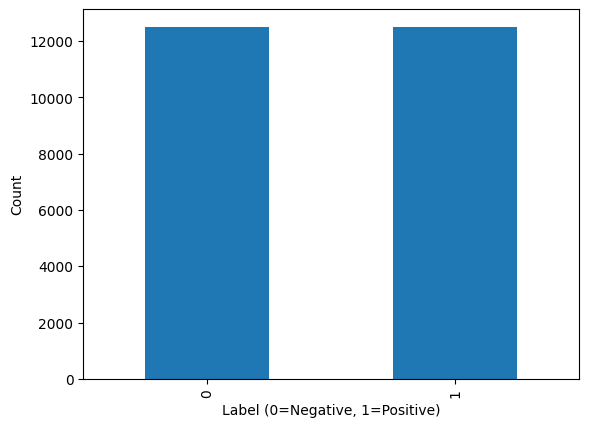

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Tokenized Training Samples: 25000
Tokenized Testing Samples: 25000
Input Shape: torch.Size([128])


In [ ]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer
print("AKHIL C - 24BAD007")
dataset = load_dataset("stanfordnlp/imdb")
train_data = dataset["train"]
test_data = dataset["test"]
print("Training Samples:", len(train_data))
print("Testing Samples:", len(test_data))
print("Sample Review:", train_data[0]["text"])
print("Sample Label:", train_data[0]["label"])
print(pd.Series(train_data["label"]).value_counts().sort_index())
pd.Series(train_data["label"]).value_counts().sort_index().plot(kind="bar")
plt.xlabel("Label (0=Negative, 1=Positive)")
plt.ylabel("Count")
plt.show()
tokenizer = AutoTokenizer.from_pretrained("google-bert/bert-base-uncased")
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128 )
tokenized_train = train_data.map(tokenize_function, batched=True)
tokenized_test = test_data.map(tokenize_function, batched=True)
tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_test = tokenized_test.rename_column("label", "labels")
tokenized_train.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"])
tokenized_test.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"])
print("Tokenized Training Samples:", len(tokenized_train))
print("Tokenized Testing Samples:", len(tokenized_test))
print("Input Shape:", tokenized_train[0]["input_ids"].shape)

PART B: Fine-Tuning BERT for Text Classification

In [ ]:
print("AKHIL C - 24BAD007")
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPaddin)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
model = AutoModelForSequenceClassification.from_pretrained(
    "google-bert/bert-base-uncased",
    num_labels=2)
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0)}
training_args = TrainingArguments(
    output_dir="./bert_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    save_total_limit=1,
    report_to="none",
    fp16=torch.cuda.is_available())
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics)
trainer.train()
results = trainer.evaluate()
print("Evaluation Results:")
for key, value in results.items():
    print(key, ":", value)
trainer.save_model("./bert_sentiment_model")
tokenizer.save_pretrained("./bert_sentiment_model")
print("BERT Model Saved")

AKHIL C - 24BAD007


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.301420,0.283484,0.887000,0.905933,0.863680,0.884302
2,0.188075,0.317327,0.893880,0.885100,0.905280,0.895076


... (3 outputs left out)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.188075,0.317327,2,0.893880,0.885100,0.905280,0.895076


Evaluation Results:
eval_loss : 0.3173273205757141
eval_accuracy : 0.89388
eval_precision : 0.8850997262416895
eval_recall : 0.90528
eval_f1 : 0.895076132094127


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT Model Saved


PART C: Sequence-to-Sequence Text Generation Using T5

In [ ]:
print("AKHIL C - 24BAD007")

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

t5_name = "google-t5/t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(t5_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(t5_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
t5_model.to(device)

def generate_summary(text, max_length=60, num_beams=4):
    inputs = t5_tokenizer(
        "summarize: " + text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():
        output = t5_model.generate(
            **inputs,
            max_new_tokens=max_length,
            num_beams=num_beams
        )

    summary = t5_tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    print("Input Text:", text)
    print("Generated Summary:", summary)
    print("-" * 50)

    return summary

text1 = "Artificial intelligence helps teachers personalize learning, automate repetitive tasks, and provide students with quick feedback."

text2 = "Renewable energy sources such as solar and wind power help reduce carbon emissions and improve sustainability."

summary1 = generate_summary(text1)
summary2 = generate_summary(text2)

results_df = pd.DataFrame({
    "Input": [text1, text2],
    "Generated Summary": [summary1, summary2]
})

results_df.to_csv("t5_generated_outputs.csv", index=False)

print(results_df)

AKHIL C - 24BAD007


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Input Text: Artificial intelligence helps teachers personalize learning, automate repetitive tasks, and provide students with quick feedback.
Generated Summary: artificial intelligence helps teachers personalize learning, automate repetitive tasks, and provide students with quick feedback.
--------------------------------------------------
Input Text: Renewable energy sources such as solar and wind power help reduce carbon emissions and improve sustainability.
Generated Summary: renewable energy sources such as solar and wind power help reduce carbon emissions and improve sustainability.
--------------------------------------------------
                                               Input  \
0  Artificial intelligence helps teachers persona...   
1  Renewable energy sources such as solar and win...   

                                   Generated Summary  
0  artificial intelligence helps teachers persona...  
1  renewable energy sources such as solar and win...  


PART D: Model Testing and Output Analysis

In [ ]:
print("AKHIL C - 24BAD007")

def predict_sentiment(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(model.device)

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
        pred = torch.argmax(probs, dim=1).item()

    sentiment = "Positive" if pred == 1 else "Negative"

    return sentiment, round(probs[0][pred].item(), 4)

reviews = [
    "This movie was amazing and entertaining.",
    "This movie was boring and disappointing.",
    "The acting was excellent and the story was wonderful.",
    "The film was terrible and a waste of time."
]

bert_results = []

for review in reviews:
    sentiment, confidence = predict_sentiment(review)

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:", confidence)
    print()

    bert_results.append({
        "Review": review,
        "Sentiment": sentiment,
        "Confidence": confidence
    })

bert_df = pd.DataFrame(bert_results)
bert_df.to_csv("bert_testing_results.csv", index=False)

print(bert_df)

AKHIL C - 24BAD007
Review: This movie was amazing and entertaining.
Predicted Sentiment: Positive
Confidence: 0.9956

Review: This movie was boring and disappointing.
Predicted Sentiment: Negative
Confidence: 0.9978

Review: The acting was excellent and the story was wonderful.
Predicted Sentiment: Positive
Confidence: 0.9956

Review: The film was terrible and a waste of time.
Predicted Sentiment: Negative
Confidence: 0.9976

                                              Review Sentiment  Confidence
0           This movie was amazing and entertaining.  Positive      0.9956
1           This movie was boring and disappointing.  Negative      0.9978
2  The acting was excellent and the story was won...  Positive      0.9956
3         The film was terrible and a waste of time.  Negative      0.9976


Evaluate BERT on the test dataset

              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89     12500
    Positive       0.89      0.91      0.90     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000



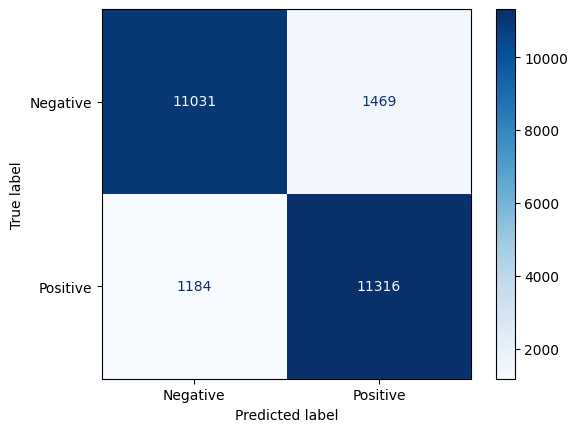

In [5]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pred_output = trainer.predict(tokenized_test)

y_true = pred_output.label_ids
y_pred = np.argmax(pred_output.predictions, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"]
))

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues")

plt.show()

Compare T5 outputs with different settings

In [6]:
sample_text = """
Machine learning is a branch of artificial intelligence.
It allows computers to learn patterns from data and make predictions.
It is used in healthcare, finance, education, and transportation.
"""

summary1 = generate_summary(
    sample_text,
    max_length=30,
    num_beams=2
)

summary2 = generate_summary(
    sample_text,
    max_length=60,
    num_beams=4
)

comparison_df = pd.DataFrame({
    "Setting": ["30 tokens, 2 beams", "60 tokens, 4 beams"],
    "Generated Output": [summary1, summary2]
})

print(comparison_df)

comparison_df.to_csv("t5_comparison_results.csv", index=False)

Input Text: 
Machine learning is a branch of artificial intelligence.
It allows computers to learn patterns from data and make predictions.
It is used in healthcare, finance, education, and transportation.

Generated Summary: machine learning is a branch of artificial intelligence. it allows computers to learn patterns from data and make predictions.
--------------------------------------------------
Input Text: 
Machine learning is a branch of artificial intelligence.
It allows computers to learn patterns from data and make predictions.
It is used in healthcare, finance, education, and transportation.

Generated Summary: machine learning is a branch of artificial intelligence. it allows computers to learn patterns from data and make predictions.
--------------------------------------------------
              Setting                                   Generated Output
0  30 tokens, 2 beams  machine learning is a branch of artificial int...
1  60 tokens, 4 beams  machine learning is a b